# Selective History Lab

Executable research pilot. The auxiliary signal is an abstract sensor, not an fMRI model. This notebook demonstrates the implementation on a small sample; the ZIP contains the separately completed 192-fit pilot and the full audit/protocol.

The public-data analyses are descriptive and do not infer responses under unexperienced teaching policies. Confidence ratings are ordinal.

In [1]:
import sys, subprocess, importlib.util
packages = {"numpy":"numpy", "scipy":"scipy", "pandas":"pandas", "numba":"numba", "matplotlib":"matplotlib", "rdata":"rdata"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Dependencies available")

Dependencies available


In [2]:
from pathlib import Path
import os, sys
project = Path("selective_history_notebook").resolve()
project.mkdir(exist_ok=True)
modules = {'history_model.py': '"""Continuing two-skill learning pilot; an abstract auxiliary sensor, not fMRI.\n\nObservations precede feedback and transitions. Assessment blocks do not change\nstate. Research logs are complete; only the personalization algorithm\'s retained history is compressed.\nThe neural interpretation requires an independently validated observation model.\n"""\nfrom dataclasses import dataclass, asdict\nimport math\nimport numpy as np\nfrom scipy.special import expit, logit\nfrom scipy.optimize import minimize\ntry:\n    from numba import njit\nexcept ImportError:\n    def njit(*args, **kwargs):\n        return lambda f: f\n\nSTATES = np.array([[0,0],[1,0],[0,1],[1,1]], dtype=np.int64)\nREQ = np.array([[1,0],[0,1],[1,1]], dtype=np.int64)\nACTIVITIES = (\'A\',\'B\',\'AB\')\n\n@dataclass(frozen=True)\nclass Config:\n    n: int = 120\n    blocks: int = 6\n    capacity: int = 18\n    epsilon: float = .10\n    initial: str = \'skewed\'\n    gains: tuple = (.08,.045,.055,.04)  # a:A, a:AB, b:B, b:AB\n    losses: tuple = (.008,.008)\n    initial_mastery: tuple = (.20,.20)\n    guess: float = .25\n    slip: float = .10\n    heterogeneity: float = .8  # persistent +/- shift of gain logits, equal mixture\n    aux_loading: float = 1.0\n    aux_sd: float = .8\n    aux_drift: float = 0.0\n    aux_subject_sd: float = 0.0\n    retention_loss: tuple = (.15,.15)\n\n@dataclass\nclass Observed:\n    action: np.ndarray\n    response: np.ndarray\n    transition: np.ndarray  # 0 identity, 1 practice, 2 overnight\n    auxiliary: np.ndarray\n    assigned_probability: np.ndarray\n    phase: np.ndarray\n\ndef retained_indices(history, rule, capacity=18):\n    if capacity < 3 or capacity % 3:\n        raise ValueError(\'Capacity must be a positive multiple of three, at least 3.\')\n    if rule == \'recency\':\n        return list(range(max(0,len(history)-capacity),len(history)))\n    if rule != \'balanced\':\n        raise ValueError(rule)\n    keep = set()\n    for e in range(3):\n        keep.update([j for j,(a,_) in enumerate(history) if a==e][-capacity//3:])\n    need = capacity-len(keep)\n    if need > 0:\n        keep.update([j for j in range(len(history)) if j not in keep][-need:])\n    return sorted(keep)\n\ndef policy(history, rule, capacity=18, epsilon=.1):\n    if rule == \'random\':\n        return np.ones(3)/3\n    if not 0 <= epsilon <= 1:\n        raise ValueError(\'epsilon outside [0,1]\')\n    retained = [history[j] for j in retained_indices(history,rule,capacity)]\n    weight = np.ones(3)\n    for e in range(3):\n        ys = [y for a,y in retained if a==e]\n        weight[e] = 1 - (1+sum(ys))/(2+len(ys))\n    return epsilon/3 + (1-epsilon)*weight/weight.sum()\n\ndef transition_matrix(gains,losses,e,shift=0):\n    effective = expit(logit(np.asarray(gains))+shift)\n    gain = np.zeros(2)\n    if e==0: gain[0]=effective[0]\n    if e==1: gain[1]=effective[2]\n    if e==2: gain[:]=effective[[1,3]]\n    out = np.ones((4,4))\n    for j,s in enumerate(STATES):\n        p = np.where(s==1,1-np.asarray(losses),gain)\n        for k,sp in enumerate(STATES):\n            out[j,k] = np.prod(np.where(sp==1,p,1-p))\n    return out\n\ndef initial_dist(p):\n    return np.prod(np.where(STATES==1,np.asarray(p),1-np.asarray(p)),axis=1)\n\ndef target(gains, heterogeneity):\n    """Standardized equal-type gain contrasts; independent of policy occupancy."""\n    rates = np.mean(expit(logit(np.asarray(gains))[None,:]+np.array([-1,1])[:,None]*heterogeneity),axis=0)\n    return rates[[1,3]]-rates[[0,2]]\n\ndef simulate(config=Config(), rule=\'recency\', seed=20261025):\n    rng=np.random.default_rng(seed); c=config\n    if rule not in (\'recency\',\'balanced\',\'random\'):\n        raise ValueError(rule)\n    if c.initial not in (\'balanced\',\'skewed\'):\n        raise ValueError(c.initial)\n    # 18 initial + probe9 + each block(12 practice + probe9), immediate24,\n    # overnight1, delayed24. Probe Z occurs once per 9-item block.\n    tmax=18+9+c.blocks*21+24+1+24\n    a=np.zeros((c.n,tmax),dtype=np.int64); y=np.full_like(a,-1)\n    trans=np.zeros_like(a); z=np.full(a.shape,np.nan)\n    prob=np.ones(a.shape); phase=np.zeros_like(a)\n    before=np.zeros_like(a); after=np.zeros_like(a); types=np.zeros(c.n)\n    for i in range(c.n):\n        u=rng.choice([-1,1]);types[i]=u\n        matrices=[transition_matrix(c.gains,c.losses,e,u*c.heterogeneity) for e in range(3)]\n        s=rng.choice(4,p=initial_dist(c.initial_mastery));hist=[];t=0\n        offset=rng.normal(0,c.aux_subject_sd)\n        def event(e,kind,ph,p=1.0,sensor=False):\n            nonlocal s,t\n            a[i,t]=e;trans[i,t]=kind;phase[i,t]=ph;prob[i,t]=p;before[i,t]=s\n            if kind==2:\n                current=STATES[s].copy()\n                current *= rng.random(2)>=np.asarray(c.retention_loss)\n                s=int(current[0]+2*current[1])\n            else:\n                eta=int(np.all(STATES[s]>=REQ[e]))\n                y[i,t]=int(rng.random()<c.guess+(1-c.slip-c.guess)*eta)\n                if sensor:\n                    z[i,t]=c.aux_loading*STATES[s].sum()+c.aux_drift*t/(tmax-1)+offset+rng.normal(0,c.aux_sd)\n                if kind==1:\n                    hist.append((e,int(y[i,t])))\n                    s=rng.choice(4,p=matrices[e][s])\n            after[i,t]=s;t+=1\n        initial=np.repeat(np.arange(3),[6,6,6] if c.initial==\'balanced\' else [12,3,3]);rng.shuffle(initial)\n        for e in initial:event(int(e),1,0)\n        for k,e in enumerate(np.tile(np.arange(3),3)):event(int(e),0,1,sensor=k==0)\n        for block in range(c.blocks):\n            positions=rng.choice(12,3,replace=False);order=rng.permutation(3)\n            scheduled=dict(zip(positions,order))\n            for j in range(12):\n                if j in scheduled:\n                    event(int(scheduled[j]),1,2)\n                else:\n                    pi=policy(hist,rule,c.capacity,c.epsilon);e=int(rng.choice(3,p=pi))\n                    event(e,1,3,float(pi[e]))\n            for k,e in enumerate(np.tile(np.arange(3),3)):event(int(e),0,1,sensor=k==0)\n        for e in np.tile(np.arange(3),8):event(int(e),0,4)\n        event(0,2,5)\n        for e in np.tile(np.arange(3),8):event(int(e),0,6)\n        assert t==tmax\n    obs=Observed(a,y,trans,z,prob,phase)\n    truth={\'before\':before,\'after\':after,\'type\':types,\'target\':target(c.gains,c.heterogeneity),\'config\':asdict(c)}\n    return obs,truth\n\ndef pack(theta, auxiliary, fixed_h, retention_loss):\n    gains=expit(theta[:4]);losses=expit(theta[4:6]);p0=expit(theta[6:8])\n    g=.5*expit(theta[8]);slip=.5*expit(theta[9])\n    mats=np.zeros((2,3,4,4))\n    for u,sgn in enumerate([-1,1]):\n        for e in range(3):mats[u,e]=transition_matrix(gains,losses,e,sgn*fixed_h)\n    p=initial_dist(p0)\n    response=np.zeros((3,4))\n    for e in range(3):\n        response[e]=g+(1-g-slip)*np.all(STATES>=REQ[e],axis=1)\n    retention=np.ones((4,4))\n    for j,s in enumerate(STATES):\n        pr=s*(1-np.array(retention_loss))\n        for k,sp in enumerate(STATES):retention[j,k]=np.prod(np.where(sp,pr,1-pr))\n    if auxiliary:\n        mu=theta[10]+np.exp(theta[11])*STATES.sum(axis=1);sd=np.exp(theta[12])\n    else:mu=np.zeros(4);sd=1.\n    return mats,p,response,retention,mu,sd\n\n@njit(cache=True,nogil=True)\ndef _forward(a,y,tr,z,mats,initial,response,retention,mu,sd,use_z):\n    out=np.zeros(a.shape[0])\n    for i in range(a.shape[0]):\n        f=np.empty((2,4))\n        for u in range(2):\n            for s in range(4):f[u,s]=.5*initial[s]\n        ll=0.\n        for t in range(a.shape[1]):\n            e=a[i,t]\n            logs=np.zeros(4)\n            for s in range(4):\n                if y[i,t]>=0:\n                    pp=response[e,s]\n                    logs[s]=math.log(pp if y[i,t]==1 else 1-pp)\n                if use_z and not math.isnan(z[i,t]):\n                    logs[s]+=-.5*((z[i,t]-mu[s])/sd)**2-math.log(sd)-.5*math.log(2*math.pi)\n            mx=np.max(logs);total=0.\n            for u in range(2):\n                for s in range(4):\n                    f[u,s]*=math.exp(logs[s]-mx);total+=f[u,s]\n            if total<=0:return np.full(a.shape[0],-1e100)\n            ll+=math.log(total)+mx\n            f/=total\n            if tr[i,t]>0:\n                nxt=np.zeros((2,4))\n                for u in range(2):\n                    for s in range(4):\n                        for sp in range(4):\n                            pp=mats[u,e,s,sp] if tr[i,t]==1 else retention[s,sp]\n                            nxt[u,sp]+=f[u,s]*pp\n                f=nxt\n        out[i]=ll\n    return out\n\ndef loglik(theta,obs,auxiliary=False,fixed_h=0.,retention_loss=(.15,.15)):\n    args=pack(theta,auxiliary,fixed_h,retention_loss)\n    return _forward(obs.action,obs.response,obs.transition,obs.auxiliary,*args,auxiliary)\n\ndef start_theta(auxiliary=False):\n    base=np.r_[logit([.06]*4),logit([.01,.01]),logit([.2,.2]),logit([.5,.2])]\n    return np.r_[base,0.,np.log(.8),np.log(1.)] if auxiliary else base\n\ndef fit(obs,auxiliary=False,fixed_h=0.,retention_loss=(.15,.15),seed=1,starts=3,maxiter=350,intervals=True):\n    """Known heterogeneity support and retention; other listed parameters learned.\n\n    fixed_h=0 gives homogeneous dynamics. fixed_h>0 is an optimistic specified-\n    mixture benchmark: it does not estimate population learning-rate heterogeneity.\n    """\n    if starts<1:raise ValueError(\'starts must be positive\')\n    rng=np.random.default_rng(seed)\n    def objective(x):return -float(loglik(x,obs,auxiliary,fixed_h,retention_loss).sum())\n    bounds=[(-7,1)]*4+[(-9,-.5)]*2+[(-5,3)]*2+[(-5,3)]*2\n    if auxiliary:bounds += [(-4,4),(-4,2),(-3,3)]\n    x0=start_theta(auxiliary); candidates=[]\n    for j in range(starts):\n        x=x0 if j==0 else x0+rng.normal(0,.55,len(x0))\n        rr=minimize(objective,x,method=\'L-BFGS-B\',bounds=bounds,options={\'maxiter\':maxiter,\'ftol\':1e-10,\'gtol\':1e-5})\n        candidates.append(rr)\n    finite=[r for r in candidates if np.isfinite(r.fun)]\n    if not finite:raise RuntimeError(\'All starts produced nonfinite likelihood\')\n    best=min(finite,key=lambda r:r.fun);x=best.x\n    est=target(expit(x[:4]),fixed_h)\n    boundary=any(min(v-lo,hi-v)<.02 for v,(lo,hi) in zip(x,bounds))\n    answer={\'estimate\':est.tolist(),\'theta\':x.tolist(),\'nll\':float(best.fun),\'converged\':bool(best.success),\'boundary\':bool(boundary),\n            \'starts\':starts,\'successful_starts\':sum(bool(r.success) for r in candidates),\'start_nll\':[float(r.fun) for r in candidates],\n            \'same_best_starts\':sum(abs(r.fun-best.fun)<1e-3 for r in candidates),\'interval_valid\':False,\'auxiliary\':auxiliary,\'fixed_h\':fixed_h,\n            \'ci_model\':None,\'ci_sandwich\':None,\'hessian_condition\':None,\'message\':str(best.message)}\n    if not intervals:return answer\n    d=len(x);h=3e-4*np.maximum(1,np.abs(x));H=np.zeros((d,d));f0=objective(x)\n    for j in range(d):\n        ej=np.zeros(d);ej[j]=h[j]\n        H[j,j]=(objective(x+ej)-2*f0+objective(x-ej))/h[j]**2\n        for k in range(j):\n            ek=np.zeros(d);ek[k]=h[k]\n            H[j,k]=H[k,j]=(objective(x+ej+ek)-objective(x+ej-ek)-objective(x-ej+ek)+objective(x-ej-ek))/(4*h[j]*h[k])\n    eig=np.linalg.eigvalsh(H)\n    condition=float(eig[-1]/eig[0]) if eig[0]>0 else float(\'inf\')\n    answer[\'hessian_condition\']=condition\n    # Refuse regular Wald intervals at a failed optimum, boundary or singularity.\n    if not best.success or boundary or eig[0]<=1e-6 or condition>1e9:return answer\n    cov=np.linalg.inv(H);scores=np.zeros((obs.action.shape[0],d));J=np.zeros((2,d))\n    for j in range(d):\n        ej=np.zeros(d);ej[j]=h[j]\n        scores[:,j]=(loglik(x+ej,obs,auxiliary,fixed_h,retention_loss)-loglik(x-ej,obs,auxiliary,fixed_h,retention_loss))/(2*h[j])\n        J[:,j]=(target(expit((x+ej)[:4]),fixed_h)-target(expit((x-ej)[:4]),fixed_h))/(2*h[j])\n    scores-=scores.mean(axis=0)\n    sandwich=cov@(scores.T@scores)@cov\n    for name,C in [(\'model\',cov),(\'sandwich\',sandwich)]:\n        v=np.diag(J@C@J.T)\n        if np.any(v<0) or not np.all(np.isfinite(v)):return answer\n        se=np.sqrt(v);answer[\'ci_\'+name]=np.column_stack([est-1.96*se,est+1.96*se]).tolist()\n    answer[\'interval_valid\']=True\n    return answer\n\ndef score_heldout(theta,obs,cutoff,auxiliary=False,fixed_h=0.,retention_loss=(.15,.15)):\n    """Sequential response predictions after cutoff, using only past Y and Z.\n\n    The auxiliary value on the current trial is incorporated only AFTER the\n    current response is predicted. Test outcomes update the filtering state;\n    they never refit parameters. This evaluates one-step-ahead prediction.\n    """\n    mats,p,resp,ret,mu,sd=pack(theta,auxiliary,fixed_h,retention_loss)\n    predicted=[];actual=[];f=np.tile(p/2,(obs.action.shape[0],2,1))\n    for t in range(obs.action.shape[1]):\n        e=obs.action[:,t];yp=obs.response[:,t]\n        pp=np.sum(f*resp[e,None,:],axis=(1,2))\n        valid=(yp>=0)\n        if t>=cutoff:\n            predicted.extend(pp[valid]);actual.extend(yp[valid])\n        loge=np.zeros((len(yp),4))\n        loge[valid]=np.where(yp[valid,None]==1,np.log(resp[e[valid]]),np.log1p(-resp[e[valid]]))\n        zv=obs.auxiliary[:,t];have=~np.isnan(zv)\n        if auxiliary:loge[have]+=-.5*((zv[have,None]-mu)/sd)**2-np.log(sd)-.5*np.log(2*np.pi)\n        loge-=loge.max(axis=1,keepdims=True)\n        f*=np.exp(loge[:,None,:]);f/=f.sum(axis=(1,2),keepdims=True)\n        for kind in (1,2):\n            idx=np.flatnonzero(obs.transition[:,t]==kind)\n            for i in idx:\n                for u in range(2):f[i,u]=f[i,u]@(mats[u,e[i]] if kind==1 else ret)\n    p=np.clip(np.asarray(predicted),1e-9,1-1e-9);yy=np.asarray(actual)\n    return {\'n_predictions\':len(p),\'brier\':float(np.mean((p-yy)**2)),\'log_loss\':float(-np.mean(yy*np.log(p)+(1-yy)*np.log1p(-p))),\n            \'mean_prediction\':float(p.mean()),\'accuracy\':float(yy.mean()),\'signed_calibration_bias\':float(p.mean()-yy.mean())}\n', 'test_model.py': '"""Executable checks of the statistical implementation, not scientific validation."""\nimport itertools\nimport unittest\nimport numpy as np\nfrom scipy.stats import norm\nfrom history_model import (Config, Observed, simulate, policy, retained_indices,\n    transition_matrix, initial_dist, target, loglik, pack, start_theta, score_heldout)\n\nclass ModelChecks(unittest.TestCase):\n    def test_transition_mass_and_forbidden_gain(self):\n        for e in range(3):\n            p = transition_matrix((.08,.045,.055,.04),(.008,.008),e)\n            np.testing.assert_allclose(p.sum(1),1)\n            self.assertTrue((p>=0).all())\n        self.assertEqual(transition_matrix((.1,)*4,(0,0),0)[0,2],0)\n\n    def test_memory_and_exploration(self):\n        h=[(0,1)]*20+[(1,0)]*5+[(2,0)]*4\n        self.assertEqual(retained_indices(h,\'recency\'),list(range(11,29)))\n        k=retained_indices(h,\'balanced\')\n        self.assertEqual(len(k),18)\n        self.assertEqual(len(set(k)),18)\n        for rule in (\'balanced\',\'recency\'):\n            p=policy(h,rule)\n            self.assertAlmostEqual(p.sum(),1)\n            self.assertGreaterEqual(p.min(),.1/3)\n\n    def test_continuity_schedule_and_no_probe_learning(self):\n        obs,truth=simulate(Config(n=6,blocks=2),seed=17)\n        np.testing.assert_array_equal(truth[\'before\'][:,1:],truth[\'after\'][:,:-1])\n        m=obs.transition==0\n        np.testing.assert_array_equal(truth[\'before\'][m],truth[\'after\'][m])\n        self.assertTrue((np.sum(obs.phase==2,axis=1)==6).all())\n        self.assertTrue((np.sum(obs.phase==3,axis=1)==18).all())\n        self.assertTrue((np.sum(np.isfinite(obs.auxiliary),axis=1)==3).all())\n        self.assertTrue((obs.assigned_probability[obs.phase==3]>=.1/3).all())\n\n    def test_forward_against_explicit_path_sum(self):\n        # Enumerate all state paths and a persistent, rather than renewed, type.\n        x=start_theta(True)\n        obs=Observed(np.array([[0,2,1]]),np.array([[1,0,1]]),\n            np.array([[1,1,0]]),np.array([[.4,np.nan,1.2]]),\n            np.ones((1,3)),np.zeros((1,3),dtype=int))\n        mats,p,resp,ret,mu,sd=pack(x,True,.8,(.15,.15))\n        total=0.\n        for u in range(2):\n            for states in itertools.product(range(4),repeat=3):\n                w=.5*p[states[0]]\n                for t,s in enumerate(states):\n                    pr=resp[obs.action[0,t],s]\n                    w*=pr if obs.response[0,t] else 1-pr\n                    if np.isfinite(obs.auxiliary[0,t]):\n                        w*=norm.pdf(obs.auxiliary[0,t],mu[s],sd)\n                    if t<2:w*=mats[u,obs.action[0,t],s,states[t+1]]\n                total+=w\n        self.assertAlmostEqual(loglik(x,obs,True,.8)[0],np.log(total),places=11)\n\n    def test_sensor_is_not_required_for_behavior_likelihood(self):\n        a,_=simulate(Config(n=3,blocks=1),seed=3)\n        b=Observed(a.action,a.response,a.transition,a.auxiliary*999,\n                   a.assigned_probability,a.phase)\n        np.testing.assert_equal(loglik(start_theta(),a),loglik(start_theta(),b))\n\n    def test_current_auxiliary_does_not_leak_into_prediction(self):\n        a=Observed(np.array([[0]]),np.array([[1]]),np.array([[0]]),\n                   np.array([[0.]]),np.ones((1,1)),np.zeros((1,1),int))\n        b=Observed(a.action,a.response,a.transition,np.array([[10.]]),\n                   a.assigned_probability,a.phase)\n        self.assertEqual(score_heldout(start_theta(True),a,0,True),\n                         score_heldout(start_theta(True),b,0,True))\n\n    def test_adaptive_counts_are_not_fixed_counts(self):\n        # Gain .2; A first, then choose A with .9 if mastered and .1 otherwise.\n        # Conditioning on AA is selection on a post-first-action state.\n        selected_no_mastery=(.8*.1*.8)/(.2*.9+.8*.1)\n        fixed_no_mastery=.8**2\n        self.assertAlmostEqual(selected_no_mastery,.2461538461538462)\n        self.assertAlmostEqual(fixed_no_mastery,.64)\n        self.assertNotAlmostEqual(selected_no_mastery,fixed_no_mastery)\n\n    def test_standardized_target(self):\n        np.testing.assert_allclose(target((.08,.045,.055,.04),0),[-.035,-.015])\n        self.assertEqual(target((.08,.045,.055,.04),.8).shape,(2,))\n\nif __name__==\'__main__\':unittest.main(verbosity=2)\n', 'public_category.py': '"""Audit and descriptive baseline for Mack, Love & Preston (2016), OSF 5byhb.\n\nNo imaging is loaded; this is not a causal adaptive-policy or neural replication.\nThe redistributed source files are CC BY 4.0; see data/public_mack/ATTRIBUTION.md.\n"""\nimport argparse, hashlib, io, json, re, urllib.request, zipfile\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\n\nSOURCES={\'description.txt\':\'https://osf.io/download/57sxd/\',\n         \'featureinfo.txt\':\'https://osf.io/download/jt5we/\',\n         \'behaviour.zip\':\'https://osf.io/download/ymdfp/\',\n         \'trialtiming.zip\':\'https://osf.io/download/25sj5/\'}\n\ndef acquire(folder):\n    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True)\n    for name,url in SOURCES.items():\n        p=folder/name\n        if not p.exists():\n            with urllib.request.urlopen(url,timeout=60) as r:data=r.read()\n            if name.endswith(\'.zip\') and not data.startswith(b\'PK\'):\n                raise ValueError(\'Expected a ZIP archive, received different content\')\n            p.write_bytes(data)\n    return folder\n\ndef load_data(folder):\n    behavior=[];timing=[]\n    columns=[\'trial\',\'task\',\'run\',\'dim1\',\'dim2\',\'dim3\',\'answer\',\'response\',\'rt_ms\',\'accuracy\']\n    with zipfile.ZipFile(folder/\'behaviour.zip\') as z:\n        names=[n for n in z.namelist() if re.search(r\'/\\d+_study\\d_run\\d\\.txt$\',n) and \'__MACOSX\' not in n]\n        for name in sorted(names):\n            sub=int(re.search(r\'/(\\d+)_study\',name)[1])\n            f=pd.read_csv(io.BytesIO(z.read(name)),sep=\'\\t\',header=None,names=columns)\n            if f.shape!=(32,10):raise ValueError(f\'Unexpected shape: {name}: {f.shape}\')\n            f.insert(0,\'subject\',sub);behavior.append(f)\n    with zipfile.ZipFile(folder/\'trialtiming.zip\') as z:\n        names=[n for n in z.namelist() if re.search(r\'/\\d+_study\\d_run\\d\\.txt$\',n) and \'__MACOSX\' not in n]\n        for name in sorted(names):\n            timing.append(pd.read_csv(io.BytesIO(z.read(name)),sep=\'\\t\',header=None,\n                names=[\'subject\',\'trial\',\'task\',\'run\',\'stimulus_onset_s\',\'feedback_onset_s\']))\n    b=pd.concat(behavior,ignore_index=True);t=pd.concat(timing,ignore_index=True)\n    keys=[\'subject\',\'task\',\'run\',\'trial\']\n    d=b.merge(t,on=keys,how=\'outer\',validate=\'one_to_one\',indicator=True)\n    if not (d[\'_merge\']==\'both\').all():raise ValueError(\'Timing/behavior records do not match\')\n    d=d.drop(columns=\'_merge\').sort_values(keys).reset_index(drop=True)\n    # The raw task/study code identifies the rule, not chronological period.\n    # Stimulus-answer mappings independently verify 1->VI, 2->I, 3->II.\n    d[\'rule\']=d.task.map({1:6,2:1,3:2})\n    d[\'period\']=np.where((d.subject%2==1)&(d.task>1),5-d.task,d.task)\n    d[\'trial_in_rule\']=(d.run-1)*32+d.trial\n    d[\'global_run\']=(d.period-1)*4+d.run\n    expected=np.where(d.rule==1,d.dim1+1,np.where(d.rule==2,(d.dim2+d.dim3)%2+1,\n                      (d.dim1+d.dim2+d.dim3)%2+1))\n    if not (d.answer==expected).all():raise ValueError(\'Category labels disagree with documentation\')\n    if not (d.accuracy==(d.response==d.answer).astype(int)).all():raise ValueError(\'Accuracy does not match responses\')\n    if d.duplicated(keys).any():raise ValueError(\'Duplicate trials\')\n    counts=d.groupby([\'subject\',\'task\',\'run\',\'dim1\',\'dim2\',\'dim3\']).size()\n    if not (counts==4).all():raise ValueError(\'Exemplar counts changed: expected four each\')\n    if not (d.feedback_onset_s>d.stimulus_onset_s).all():raise ValueError(\'Invalid timing order\')\n    return d.sort_values([\'subject\',\'period\',\'run\',\'trial\']).reset_index(drop=True)\n\ndef run(folder,out):\n    folder=acquire(folder);out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    d=load_data(folder);d.to_csv(out/\'events.csv\',index=False)\n    rng=np.random.default_rng(20261025);rows=[]\n    for sample,dd in [(\'all_behavior\',d),(\'exclude_subject_09\',d[d.subject!=9])]:\n        for (rule,run),g in dd.groupby([\'rule\',\'run\']):\n            a=g.groupby(\'subject\').accuracy.mean().to_numpy()\n            boot=np.mean(rng.choice(a,size=(2000,len(a)),replace=True),axis=1)\n            rows.append({\'sample\':sample,\'rule\':int(rule),\'run\':int(run),\'participants\':len(a),\n                \'accuracy\':float(a.mean()),\'lower\':float(np.quantile(boot,.025)),\n                \'upper\':float(np.quantile(boot,.975))})\n    summary=pd.DataFrame(rows);summary.to_csv(out/\'learning_curves.csv\',index=False)\n    fig,ax=plt.subplots(figsize=(7.4,4.3),layout=\'constrained\')\n    for rule,color in [(1,\'#176b9b\'),(2,\'#bc7423\'),(6,\'#73549b\')]:\n        s=summary[(summary[\'sample\']==\'all_behavior\')&(summary.rule==rule)]\n        ax.plot(s.run,s.accuracy,\'o-\',color=color,label=f\'Type {rule}\')\n        ax.fill_between(s.run,s.lower,s.upper,color=color,alpha=.12)\n    ax.set(xlabel=\'Run within category rule (32 trials per run)\',ylabel=\'Mean accuracy\',\n           ylim=(.35,1.02),xticks=[1,2,3,4],title=\'Public category-learning baseline: 23 participants\')\n    ax.axhline(.5,color=\'.6\',linestyle=\':\',linewidth=1);ax.legend(frameon=False)\n    ax.spines[[\'top\',\'right\']].set_visible(False)\n    fig.savefig(out/\'learning_curves.png\',dpi=180);plt.close(fig)\n    checks={\'participants\':int(d.subject.nunique()),\'trials\':len(d),\'runs\':int(d.groupby([\'subject\',\'task\',\'run\']).ngroups),\n        \'trials_per_run\':32,\'repetitions_per_exemplar\':4,\'omissions\':int(d.response.isna().sum()),\n        \'missing_rt\':int(d.rt_ms.isna().sum()),\'label_mismatches\':0,\'timing_join\':\'one-to-one, all rows matched\',\n        \'accuracy_includes_omissions_as_incorrect\':True,\'subject09_in_behavior\':True,\n        \'sensitivity_excludes_subject09\':True,\'type6_always_first\':True,\n        \'task_code_is_chronology\':False,\'task_code_to_rule\':{\'1\':6,\'2\':1,\'3\':2},\n        \'period_mapping\':\'even subjects VI/I/II; odd subjects VI/II/I, per source README\',\n        \'neural_files_processed\':0,\'confidence_measure_available\':False,\n        \'inference\':\'descriptive, not an adaptive-policy causal effect\',\n        \'bootstrap\':\'2,000 participant resamples per rule/run; pointwise percentile intervals, not simultaneous\',\n        \'documentation_discrepancy\':\'README says three repetitions; files contain four per eight stimuli in each 32-trial run\'}\n    (out/\'audit.json\').write_text(json.dumps(checks,indent=2))\n    (out/\'provenance.json\').write_text(json.dumps({\'retrieved\':\'2026-10-25\',\'project\':\'https://osf.io/5byhb/\',\n        \'authors\':\'Mack, Love & Preston (2016)\',\'license\':\'CC BY 4.0\',\n        \'files\':[{\'name\':k,\'url\':v,\'sha256\':hashlib.sha256((folder/k).read_bytes()).hexdigest(),\n                  \'bytes\':(folder/k).stat().st_size} for k,v in SOURCES.items()]},indent=2))\n    print(json.dumps(checks,indent=2));return d,summary,checks\n\nif __name__==\'__main__\':\n    ap=argparse.ArgumentParser();ap.add_argument(\'--data\',default=\'data/public_mack\');ap.add_argument(\'--out\',default=\'outputs/public_category\')\n    a=ap.parse_args();run(a.data,a.out)\n', 'public_personalization.py': '"""Descriptive checks of Bahg, Sloutsky & Turner (2025), OSF n2mxu.\n\nUses the released processed aggregate, not a reproduction of raw exclusions.\nConfidence is ordinal; no probability calibration is inferred from its scale.\n"""\nimport argparse,hashlib,json,urllib.request\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport rdata\n\nSOURCE=\'https://osf.io/download/rzm7g/\'\nLABELS={\'control\':\'Control\',\'active\':\'AL\',\'curationRS\':\'PR\',\'curationOS\':\'PP\',\'curationAS\':\'PA\'}\n\ndef run(source,out):\n    source=Path(source);out=Path(out);out.mkdir(exist_ok=True,parents=True)\n    if not source.exists():\n        source.parent.mkdir(exist_ok=True,parents=True)\n        source.write_bytes(urllib.request.urlopen(SOURCE,timeout=60).read())\n    objects=rdata.read_rda(source);d=objects[\'dat.complete\'].copy()\n    d.columns=[str(x) for x in d.columns]\n    if len(d)!=9600 or d.subject.nunique()!=300:raise ValueError(\'Source aggregate changed\')\n    if not (d.groupby(\'subject\',observed=True).size()==32).all():raise ValueError(\'Unexpected test counts\')\n    if not d.CONF.between(1,11).all():raise ValueError(\'Unexpected confidence coding\')\n    if not (d.ACCnumeric==(d.ACC.astype(str)==\'correct\').astype(int)).all():raise ValueError(\'Accuracy mismatch\')\n    if not (d.PRSNT.astype(str)==np.where(d.RPRSNT>3,\'presented\',\'notpresented\')).all():\n        raise ValueError(\'Exposure label no longer matches threshold\')\n    # Author processing code adds one to the original 0..10 rating.\n    d[\'confidence_rating\']=d.CONF-1\n    d[\'condition\']=d.COND.astype(str).map(LABELS)\n    d[\'exposure_group\']=np.where(d.RPRSNT==0,\'zero\',np.where(d.RPRSNT<4,\'one_to_three\',\'four_or_more\'))\n    p=d.groupby([\'STIM\',\'condition\',\'subject\'],observed=True).agg(\n        accuracy=(\'ACCnumeric\',\'mean\'),confidence=(\'confidence_rating\',\'mean\'),\n        sampled_dimensions=(\'MEAN_N_ENCODED\',\'first\'),exposure_entropy=(\'ENTROPY\',\'first\')).reset_index()\n    error=d[d.ACCnumeric==0].groupby(\'subject\',observed=True).confidence_rating.mean()\n    p[\'confidence_on_errors\']=p.subject.map(error)\n    s=p.groupby([\'STIM\',\'condition\'],observed=True).agg(participants=(\'subject\',\'nunique\'),\n        accuracy=(\'accuracy\',\'mean\'),mean_confidence=(\'confidence\',\'mean\'),\n        mean_confidence_on_errors=(\'confidence_on_errors\',\'mean\'),\n        participants_with_errors=(\'confidence_on_errors\',\'count\'),\n        mean_sampled_dimensions=(\'sampled_dimensions\',\'mean\'),\n        mean_exposure_entropy=(\'exposure_entropy\',\'mean\')).reset_index()\n    s.to_csv(out/\'condition_summary.csv\',index=False)\n    # Retain participant clustering in descriptive exposure summaries.\n    e=d.groupby([\'STIM\',\'condition\',\'subject\',\'exposure_group\'],observed=True).agg(\n        trials=(\'ACCnumeric\',\'size\'),accuracy=(\'ACCnumeric\',\'mean\'),\n        confidence=(\'confidence_rating\',\'mean\')).reset_index()\n    es=e.groupby([\'STIM\',\'condition\',\'exposure_group\'],observed=True).agg(\n        participants=(\'subject\',\'nunique\'),trials=(\'trials\',\'sum\'),accuracy=(\'accuracy\',\'mean\'),\n        confidence=(\'confidence\',\'mean\')).reset_index()\n    es.to_csv(out/\'exposure_summary.csv\',index=False)\n    audit={\'source\':SOURCE,\'project\':\'https://osf.io/n2mxu/\',\'retrieved\':\'2026-10-25\',\n        \'sha256\':hashlib.sha256(source.read_bytes()).hexdigest(),\'source_bytes\':source.stat().st_size,\n        \'participants_in_processed_aggregate\':300,\'test_rows\':9600,\'cells\':15,\'participants_per_cell\':20,\n        \'test_rows_per_person\':32,\'original_confidence_scale\':\'0 to 10; ordinal, not assumed a probability\',\n        \'released_CONF_coding\':\'1 to 11; original processing script adds one\',\n        \'underexposure_label\':\'notpresented in the source means fewer than four training presentations, not necessarily zero\',\n        \'source_exclusion_pipeline_reproduced\':False,\'new_causal_effect_estimated\':False,\n        \'raw_source_redistributed\':False,\'license_note\':\'No project license recorded in inspected OSF metadata; downloader provided instead of raw-file redistribution\'}\n    (out/\'audit.json\').write_text(json.dumps(audit,indent=2))\n    print(json.dumps(audit,indent=2));return s,es,audit\n\nif __name__==\'__main__\':\n    ap=argparse.ArgumentParser();ap.add_argument(\'--data\',default=\'data/cache_bahg/dat_all.Rdata\');ap.add_argument(\'--out\',default=\'outputs/public_personalization\')\n    a=ap.parse_args();run(a.data,a.out)\n'}
for name, source in modules.items():
    (project / name).write_text(source)
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
print("Research modules written to", project.name)

Research modules written to selective_history_notebook


## Check the implementation
The forward likelihood is checked against explicit latent-state path enumeration; other checks cover state continuity, policy support and prediction leakage.

In [3]:
import unittest
import test_model
suite = unittest.defaultTestLoader.loadTestsFromModule(test_model)
result = unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful()

........
----------------------------------------------------------------------
Ran 8 tests in 1.313s

OK


## Demonstrate one continuing trajectory model
The specified mixture assumes known type separation and overnight retention. One small fit cannot establish recovery or coverage.

In [4]:
from history_model import Config, simulate, fit, score_heldout
config = Config(n=40, blocks=2)
observed, truth = simulate(config, rule="recency", seed=7301)
fitted = fit(observed, auxiliary=True, fixed_h=.8, starts=2, seed=7302)
print("Generating contrasts:", truth["target"].round(4))
print("Estimated contrasts:", [round(x,4) for x in fitted["estimate"]])
print("Converged:", fitted["converged"], "Valid regular intervals:", fitted["interval_valid"])
print("Model intervals:", fitted["ci_model"])

Generating contrasts: [-0.0421 -0.0185]
Estimated contrasts: [-0.0437, -0.0387]
Converged: True Valid regular intervals: True
Model intervals: [[-0.14603389796744307, 0.05862382057574414], [-0.13776091759096365, 0.060373627115661535]]


In [5]:
test_observed, _ = simulate(config, rule="random", seed=7303)
score_heldout(fitted["theta"], test_observed, cutoff=27, auxiliary=True, fixed_h=.8)

Out[0]: 
{'n_predictions': 3600,
 'brier': 0.14952859633158969,
 'log_loss': 0.4706528589578583,
 'mean_prediction': 0.5593444357249944,
 'accuracy': 0.5452777777777778,
 'signed_calibration_bias': 0.014066657947216621}


## Audit the public category data
The following source archives are embedded unchanged under CC BY 4.0. Attribution: Mack, Love & Preston (2016), https://doi.org/10.1073/pnas.1614048113, https://osf.io/5byhb/. Only behavior and timing are included; no MRI volumes are loaded.

In [6]:
import base64
from public_category import run as run_category
source_dir = project / "data/public_mack"
source_dir.mkdir(parents=True, exist_ok=True)
archives = {'description.txt': 'UGFydGljaXBhbnRzIGxlYXJuZWQgdGhyZWUgY2F0ZWdvcnkgbGVhcm5pbmcgdGFza3MgZHVyaW5nIGZNUkkgc2Nhbm5pbmcuIEVhY2ggdGFzayBjb25zaXN0ZWQgb2YgNCBmTVJJIHJ1bnMsIGVhY2ggd2l0aCAzMiB0cmlhbHMuIEFjcm9zcyB0aGVzZSAzMiB0cmlhbHMsIHRoZSA4IHN0aW11bGkgd2VyZSByZXBlYXRlZCAzIHRpbWVzIGluIHJhbmRvbSBvcmRlci4gCgpOT1RFOiBTdWJqZWN0IDkncyBydW4gNSBmdW5jdGlvbmFsIGRhdGEgKGZ1bmN0aW9uYWxfNS9ib2xkLm5paS5neikgaXMgY29ycnVwdGVkIGFuZCBzaG91bGQgYmUgZXhjbHVkZWQgZnJvbSBhbmFseXNlcy4gCgpEZXRhaWxzIGZvciB0aGUgYmVoYXZpb3VyYWwgZGF0YSBmaWxlIGZvcm1hdCwgdGFzayBvcmRlciwgY2F0ZWdvcnkgc3RydWN0dXJlcyBvZiB0aGUgdGFza3MsIGFuZCB0aGUgaW1hZ2luZyBkYXRhIGFyZSBhcyBmb2xsb3dzOgoKKiogYmVoYXZpb3VyYWwgZGF0YSBmaWxlIGNvbHVtbnMgKiogCjEuIHRyaWFsIG51bWJlciAoMS0zMikKMi4gdGFzayAoMS0zKQozLiBydW4gKDEtNCkKNC4gZGltZW5zaW9uIDEKNS4gZGltZW5zaW9uIDIKNi4gZGltZW5zaW9uIDMKNy4gYW5zd2VyICgxIG9yIDIpCjguIHJlc3BvbnNlICgxIG9yIDIpCjkuIFJUIChtcykKMTAuIGFjY3VyYWN5ICgwIG9yIDEpCgoKKiogdHJpYWwgdGltaW5nIGZpbGUgY29sdW1ucyAqKgoxLiBzdWJqZWN0CjIuIHRyaWFsICgxLTMyKQoyLiB0YXNrICgxLTMpCjMuIHJ1biAoMS00KQo0LiBzdGltdWx1cyBvbnNldAo1LiBmZWVkYmFjayBvbnNldAoKCioqIG9yZGVyIG9mIHRhc2sgdHlwZXMgKioKZXZlbiBzdWJqZWN0IG51bWJlcnM6IHR5cGUgNiwgdHlwZSAxLCB0eXBlIDIKb2RkIHN1YmplY3QgbnVtYmVyczogdHlwZSA2LCB0eXBlIDIsIHR5cGUgMQoKCioqIGNhdGVnb3J5IHN0cnVjdHVyZXMgKioKdHlwZXMgMSwgMiwgYW5kIDYgZnJvbSBTaGVwYXJkLCBIb3ZsYW5kLCAmIEplbmtpbnMsIDE5NjEKIHN0aW11bHVzIGRpbWVuc2lvbiB8ICAgICAgICBjYXRlZ29yeQpkaW0gMSAgZGltIDIgIGRpbSAzIHwgdHlwZSAxICB0eXBlIDIgIHR5cGUgNgogIDAgICAgICAwICAgICAgMCAgIHwgICAxICAgICAgIDEgICAgICAgMQogIDAgICAgICAwICAgICAgMSAgIHwgICAxICAgICAgIDIgICAgICAgMgogIDAgICAgICAxICAgICAgMCAgIHwgICAxICAgICAgIDIgICAgICAgMgogIDAgICAgICAxICAgICAgMSAgIHwgICAxICAgICAgIDEgICAgICAgMQogIDEgICAgICAwICAgICAgMCAgIHwgICAyICAgICAgIDEgICAgICAgMgogIDEgICAgICAwICAgICAgMSAgIHwgICAyICAgICAgIDIgICAgICAgMQogIDEgICAgICAxICAgICAgMCAgIHwgICAyICAgICAgIDIgICAgICAgMQogIDEgICAgICAxICAgICAgMSAgIHwgICAyICAgICAgIDEgICAgICAgMgoKCioqIGZlYXR1cmVzIHRvIGRpbWVuc2lvbiBhc3NpZ25tZW50ICoqClRoZSBmZWF0dXJlaW5mby50eHQgZmlsZSBwcm92aWRlcyBob3cgdGhlIGZlYXR1cmVzIHdlcmUgYXNzaWduZWQgdG8gdGhlIHRocmVlIGRpbWVuc2lvbnMgZm9yIGVhY2ggc3ViamVjdC4gCgoKKiogaW1hZ2luZyBkYXRhICoqCldpdGhpbiBlYWNoIHBhcnRpY2lwYW50IGRhdGEgdGFyIGZpbGUgYXJlOgogIC0gMW1tLWlzbyBNUFJBR0UgKGhpZ2hyZXMubmlpLmd6KQogIC0gMiBjb3JvbmFsbHktb3JpZW50ZWQgVDIgKGNvcm9uYWwxLzIubmlpLmd6KQogIC0gRmllbGRtYXAgKGZpZWxkbWFwX21hZy5uaWkuZ3osIGZpZWxkbWFwX3BoYXNlLm5paS5neikKICAtIDEyIGZ1bmN0aW9uYWwgdGltZXNlcmllcyAoZnVuY3Rpb25hbF97MS4uMTJ9L2JvbGQubmlpLmd6Ck5PVEU6IFN1YmplY3QgOSdzIHJ1biA1IGZ1bmN0aW9uYWwgZGF0YSAoZnVuY3Rpb25hbF81L2JvbGQubmlpLmd6KSBpcyBjb3JydXB0ZWQgYW5kIHNob3VsZCBiZSBleGNsdWRlZCBmcm9tIGFueSBhbmFseXNlcy4gCg==', 'featureinfo.txt': 'RmVhdHVyZSB0byBkaW1lbnNpb24gaW5mb3JtYXRpb24KCmZlYXR1cmVzOgoxIC0gbGVnCjIgLSBhbnRlbm5hCjMgLSBtYW5kaWJsZQoKZmVhdHVyZSB2YWx1ZXM6CmxlZyAtIDE6dGhpbiwgMjp0aGljawphbnRlbm5hIC0gMTp0aGljaywgMjp0aGluCm1hbmRpYmxlOiAxOnBpbmNlciwgMjpzaG92ZWwKClRoZSB0YWJsZSBiZWxvdyBoYXMsIGZvciBlYWNoIHN1YmplY3QsIHRoZSBmZWF0dXJlIGFzc2lnbmVkCnRvIGVhY2ggZGltZW5zaW9uIChkaW0xLWRpbTMpLCBhbmQgdGhlIGZlYXR1cmUgdmFsdWVzIGFzc2lnbmVkCnRvIHRoZSBkaW1lbnNpb25zICh2YWwxLXZhbDM7IGUuZy4sIDIxIGZvciBsZWdzIG1lYW5zIHRoaWNrCmxlZ3Mgd2VyZSBhc3NpZ25lZCB0byB2YWx1ZSAwLCBhbmQgdGhpbiBsZWdzIHRvIHZhbHVlIDEpLgoKc2JqLGRpbTEsZGltMixkaW0zLHZhbDEsdmFsMix2YWwzCjAyLDIsMSwzLDEyLDEyLDEyCjAzLDMsMSwyLDEyLDEyLDEyCjA0LDEsMiwzLDIxLDIxLDEyCjA1LDMsMiwxLDEyLDEyLDIxCjA2LDMsMSwyLDIxLDEyLDIxCjA3LDMsMSwyLDEyLDIxLDEyCjA4LDMsMiwxLDIxLDEyLDEyCjA5LDEsMiwzLDEyLDIxLDIxCjEwLDIsMywxLDEyLDEyLDEyCjExLDEsMywyLDIxLDEyLDIxCjEyLDMsMiwxLDEyLDEyLDIxCjEzLDEsMiwzLDIxLDIxLDIxCjE0LDIsMywxLDEyLDEyLDIxCjE1LDEsMiwzLDEyLDEyLDIxCjE2LDIsMywxLDEyLDIxLDIxCjE3LDMsMSwyLDEyLDEyLDIxCjE4LDIsMSwzLDIxLDIxLDEyCjE5LDIsMSwzLDIxLDEyLDEyCjIwLDMsMSwyLDEyLDEyLDEyCjIxLDEsMywyLDIxLDIxLDEyCjIyLDEsMywyLDIxLDEyLDIxCjIzLDIsMywxLDEyLDIxLDEyCjI0LDIsMSwzLDEyLDIxLDIxCg==', 'behaviour.zip': '...', 'trialtiming.zip': '...'}
for name, encoded in archives.items():
    (source_dir / name).write_bytes(base64.b64decode(encoded))
events, curves, category_audit = run_category(source_dir, project / "outputs/public_category")
curves.head()

{
  "participants": 23,
  "trials": 8832,
  "runs": 276,
  "trials_per_run": 32,
  "repetitions_per_exemplar": 4,
  "omissions": 53,
  "missing_rt": 53,
  "label_mismatches": 0,
  "timing_join": "one-to-one, all rows matched",
  "accuracy_includes_omissions_as_incorrect": true,
  "subject09_in_behavior": true,
  "sensitivity_excludes_subject09": true,
  "type6_always_first": true,
  "task_code_is_chronology": false,
  "task_code_to_rule": {
    "1": 6,
    "2": 1,
    "3": 2
  },
  "period_mapping": "even subjects VI/I/II; odd subjects VI/II/I, per source README",
  "neural_files_processed": 0,
  "confidence_measure_available": false,
  "inference": "descriptive, not an adaptive-policy causal effect",
  "bootstrap": "2,000 participant resamples per rule/run; pointwise percentile intervals, not simultaneous",
  "documentation_discrepancy": "README says three repetitions; files contain four per eight stimuli in each 32-trial run"
}
Out[0]: 
         sample  rule  run  participants  accur

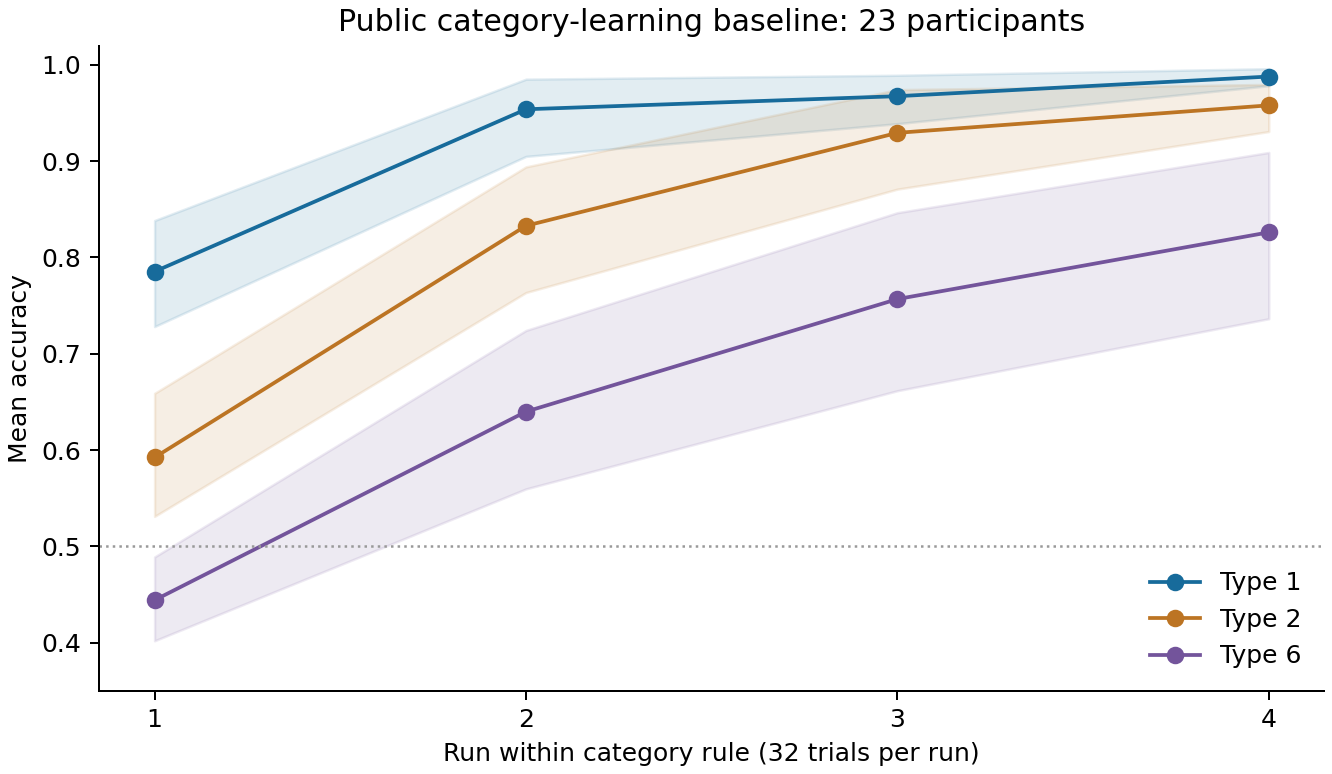

In [7]:
from IPython.display import Image, display
display(Image(filename=str(project / "outputs/public_category/learning_curves.png")))

## Audit public personalization data
This cell downloads the authors' processed aggregate from OSF. It does not redistribute the source file or reconstruct raw participant exclusions. The source coding adds one to the original 0–10 confidence rating. “Not presented” in the source includes one to three presentations; the audit distinguishes these from zero.

In [8]:
from public_personalization import run as run_personalization
condition_summary, exposure_summary, personalization_audit = run_personalization(
    project / "data/cache_bahg/dat_all.Rdata", project / "outputs/public_personalization")
condition_summary

{
  "source": "https://osf.io/download/rzm7g/",
  "project": "https://osf.io/n2mxu/",
  "retrieved": "2026-10-25",
  "sha256": "45ee082288c1bc59c8512168065e60cc8947da8c7b9a42d588f2ce19ad9e227d",
  "source_bytes": 243437,
  "participants_in_processed_aggregate": 300,
  "test_rows": 9600,
  "cells": 15,
  "participants_per_cell": 20,
  "test_rows_per_person": 32,
  "original_confidence_scale": "0 to 10; ordinal, not assumed a probability",
  "released_CONF_coding": "1 to 11; original processing script adds one",
  "underexposure_label": "notpresented in the source means fewer than four training presentations, not necessarily zero",
  "source_exclusion_pipeline_reproduced": false,
  "new_causal_effect_estimated": false,
  "raw_source_redistributed": false,
  "license_note": "No project license recorded in inspected OSF metadata; downloader provided instead of raw-file redistribution"
}
Out[0]: 
            STIM condition  ...  mean_sampled_dimensions  mean_exposure_entropy
0        cluste

## Interpret the completed pilot cautiously
The delivered ZIP contains 12 replications in each policy/sensor setting, 120 synthetic participants per dataset, and 192 fits. Sensor perturbations share latent trajectories and responses. All fits passed the implemented optimization and regular-Wald checks. This is implementation evidence, not a validated sample-size recommendation.

For the specified-mixture recency model with an invariant sensor, skill-a RMSE was .01906 with behavior alone and .01844 with the sensor; mean interval width was .09557 and .09548. These differences do not demonstrate meaningful inferential rescue. Even coverage of 12/12 has a 95% exact Monte Carlo interval of approximately [.735, 1].

The full study still needs unknown-heterogeneity estimation, cost-matched behavioral baselines, realistic neural observation models, stronger misspecification checks and a preregistered precision target.